# Introduction to the Clustering of Texts

Text clustering is widely used in many applications such as recommender systems, sentiment analysis, topic selection or user segmentation. Word embeddings allow to exploit the ordering of words and semantics information from the text corpus. But what are word embeddings exactly? Loosely speaking, they are vector representations of a particular word. Words cannot naively be passed to a neural network (or other machine learning algorithm), they must first be encoded into some kind of numerical form fit for input. We can think of words as being distinct inputs, which nevertheless have some kind of relationship with one another in some kind of abstract space of meanings. For example the words "princess" and "queen" are close to one another in meaning, while the words "ball" and "square" are far away.
There are a number of different approaches to generating word embeddings, whose relative merit is based on how good they are at placing words in vector space close to one another. The approaches can be split into roughly two categories: probabilistic approaches (e.g. using a neural network to optimize an embedding), and classical "count-based" approaches.
In this notebook we are going to use two embedding algorithms:

- **Word2Vec** is one of the most popular techniques to learn word embeddings using shallow neural networks. It was developed by Tomas Mikolov in 2013 at Google.

- **GloVe** is an unsupervised learning algorithm for obtaining vector representations for words. Training is performed on aggregated global word-word co-occurrence statistics from a corpus, and the resulting representations showcase interesting linear substructures of the word vector space.



## Learning Objectives

At the end of this notebook, you should be able to:

- Construct sentence embeddings by averaging Word2Vec or GloVe word vectors.
- Apply K-Means, MiniBatchKMeans, and Agglomerative clustering to embedded text.
- Evaluate clustering against known labels using a confusion matrix, accuracy, and the Rand index.
- Compare the three algorithms on the same text dataset.


In [1]:
import pandas as pd
import numpy as np
import string
import sys
import re

import nltk

nltk.download("stopwords")
from nltk.corpus import stopwords
from nltk.cluster import KMeansClusterer

from sklearn.datasets import fetch_20newsgroups
from sklearn.metrics import confusion_matrix, classification_report, rand_score, accuracy_score
from sklearn import metrics
from sklearn.cluster import DBSCAN, MiniBatchKMeans, KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

import gensim.downloader
from gensim.models import KeyedVectors
from gensim.models import Word2Vec

import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (15, 10)

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/rouzbehenayatzadeh/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


For the embeddings we will use the gensim word2vec model. Clustering works at the sentence level, so there is one extra step to move from word level to sentence level. For each sentence, we sum the word embedding of every word and divide by the number of words. This gives the average of all word embeddings for the sentence, which we then use just as we would use word-level embeddings: as the input to a clustering algorithm.


Now we will cluster our text using the Kmeans algorithm with the word2vec model for embeddings. For this we will use `KMeansClusterer`, the Kmeans implementation from the NLTK library. 

In [2]:
# Saving the sentences as a list
sentences = [
    ["this", "is", "the", "one", "good", "machine", "learning", "book"],
    ["this", "is", "another", "book"],
    ["another", "book", "in", "collection"],
    ["weather", "rain", "snow"],
    ["yesterday", "weather", "snow"],
    ["forecast", "tomorrow", "rain", "snow"],
    ["tomorrow", "weather", "clear"],
    ["this", "is", "the", "new", "post"],
    ["this", "is", "about", "more", "machine", "learning", "post"],
    ["and", "this", "is", "the", "one", "last", "post", "book"],
]


# Importing the word2vec model
model = Word2Vec(sentences, min_count=1)


# Creating a function that calculates the embeddings for the whole sentence by sum up the embedding of
# each word und divide it by the sum of words in the sentence
def sent_vectorizer(sent, model):
    sent_vec = []
    numw = 0
    for w in sent:
        try:
            if numw == 0:
                sent_vec = model.wv[w]
            else:
                sent_vec = np.add(sent_vec, model.wv[w])
            numw += 1
        except:
            pass

    return np.asarray(sent_vec) / numw


# Saving the embeddings into a list X
X = []
for sentence in sentences:
    X.append(sent_vectorizer(sentence, model))


# Creating the KMeans Clustering model with the implementation of the nltk library
NUM_CLUSTERS = 2
kclusterer = KMeansClusterer(NUM_CLUSTERS, distance=nltk.cluster.util.cosine_distance, repeats=50)
assigned_clusters = kclusterer.cluster(X, assign_clusters=True)

1 ['this', 'is', 'the', 'one', 'good', 'machine', 'learning', 'book']
1 ['this', 'is', 'another', 'book']
1 ['another', 'book', 'in', 'collection']
0 ['weather', 'rain', 'snow']
0 ['yesterday', 'weather', 'snow']
0 ['forecast', 'tomorrow', 'rain', 'snow']
0 ['tomorrow', 'weather', 'clear']
1 ['this', 'is', 'the', 'new', 'post']
1 ['this', 'is', 'about', 'more', 'machine', 'learning', 'post']
1 ['and', 'this', 'is', 'the', 'one', 'last', 'post', 'book']


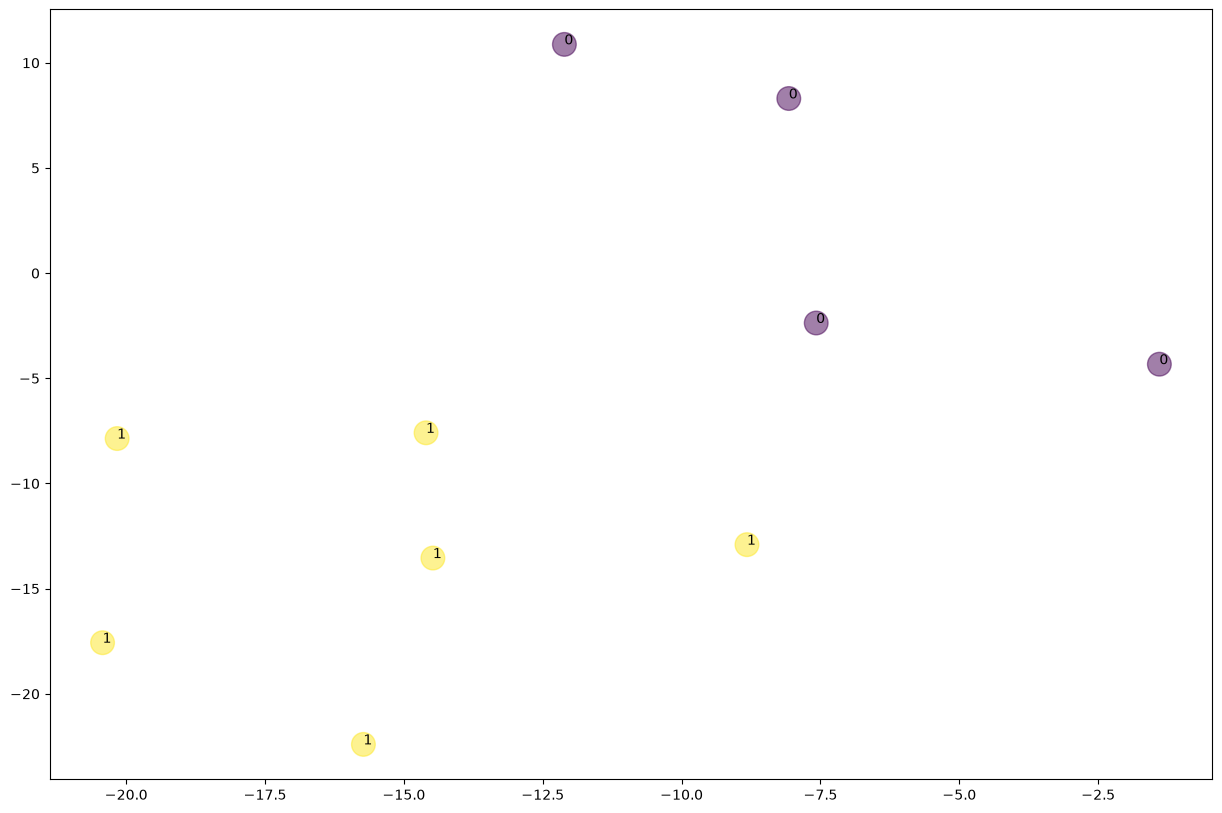

In [3]:
# If you look at our data X you see that it has more than 2 dimensions
# In order to plot the data we will use t-SNE to reduce the dimensions to 2
model = TSNE(n_components=2, perplexity=5, random_state=0)
np.set_printoptions(suppress=True)

Y = model.fit_transform(pd.DataFrame(X))

# Plotting the results of the clustering
plt.scatter(Y[:, 0], Y[:, 1], c=assigned_clusters, s=290, alpha=0.5)

for j in range(len(sentences)):
    plt.annotate(assigned_clusters[j], xy=(Y[j][0], Y[j][1]), xytext=(0, 0), textcoords="offset points")
    print("%s %s" % (assigned_clusters[j], sentences[j]))

plt.show();

The sentences were clustered by topic, as we hoped: the book and machine-learning sentences fall in one cluster and the weather sentences in the other. This small example shows the full recipe: build word embeddings with Word2Vec, average them into a sentence embedding, then cluster the sentence embeddings with K-Means.


## Several Clustering Algorithms in Combination with GloVe

`GloVe` stands for Global Vectors for Word Representations and it's a relatively new state of the art natural language processing technique of creating vector space models of word semantics, more commonly known as word embeddings. GloVe is an unsupervised algorithm developed by Stanford University that aims at generating word embeddings by aggregating global word-word co-occurrence matrix from a corpus. GloVe is similar to Word2Vec with the primary difference being that Word2Vec is a 'predictive' model that predicts context given a word while GloVe is a count-based model that learns the vectors by essentially doing dimensionality reduction on the co-occurrence counts matrix with respect to minimizing a cost function.

We will use 2 categories from the 20 News Groups dataset as our data. The we are going to use and compare `KMeans Clustering`, `MiniBatchKMeans` and `Agglomerative Clustering` as our clustering algorithms. 

The pipeline for the GloVe experiments below is:

```mermaid
flowchart LR
    A[Raw text documents] --> B[Clean and remove stopwords]
    B --> C[GloVe word vectors]
    C --> D[Average to a sentence vector]
    D --> E[Scale, then PCA]
    E --> F[Cluster: KMeans / MiniBatch / Agglomerative]
```


In [4]:
# Downloading the GLoVe Pre-trained Vectorizer
glove_vectors = gensim.downloader.load("glove-wiki-gigaword-50")

[==================================================] 100.0% 66.0/66.0MB downloaded


In [5]:
# Downloading the 20 Newsgroups Dataset
data = fetch_20newsgroups()

In [6]:
# Keeping only two Categories (atheism and autos) of the Newsgroup dataset
# (Feel free to experiment also with other categories)
categories = ["alt.atheism", "rec.autos"]
data = fetch_20newsgroups(categories=categories)

In [7]:
# Preprocess the data
sentences = []
for sentence in data.data:
    # Removing punctuation and special characters
    sentence = re.sub(r"[^A-Za-z0-9]+", " ", sentence)
    # Removing the stopwords
    stop = stopwords.words("english")
    sentence = sentence.split()
    resultwords = [word for word in sentence if word.lower() not in stop]
    sentences.append(" ".join(resultwords))

In [8]:
# Creating a function that calculates the embeddings for the whole sentence by summing up the embedding of
# each word und dividing it by the sum of words in the sentence
def sent_vectorizer(sent, model):
    sent_vec = []
    numw = 0
    values = sent.split()
    for w in values:
        try:
            if numw == 0:
                sent_vec = model[w]
            else:
                sent_vec = np.add(sent_vec, model[w])
            numw += 1
        except:
            pass

    return np.asarray(sent_vec) / numw


# Saving the embeddings in a list X
X = []
for sentence in sentences:
    X.append(sent_vectorizer(sentence, glove_vectors))

In [9]:
print("Number of targets: ", len(data.target))
print("Number of Sentences: ", len(sentences))
print("Number of X: ", len(X))

Number of targets:  1074
Number of Sentences:  1074
Number of X:  1074


In [10]:
# Using PCA for Dimensionality Reduction
# And the StandardScaler to scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pca_ = PCA(0.99, random_state=0)
X_pca = pca_.fit_transform(X_scaled)

### KMeans

First we will use the `KMeans` clustering algorithm. We will look at the `Elbow Method` to have a look how many clusters we should choose. The y-axis of our plot represents the WCSS which is the *"within-cluster sum of squares"*. These are the sum of squared distances from observations within a cluster to their centroid.

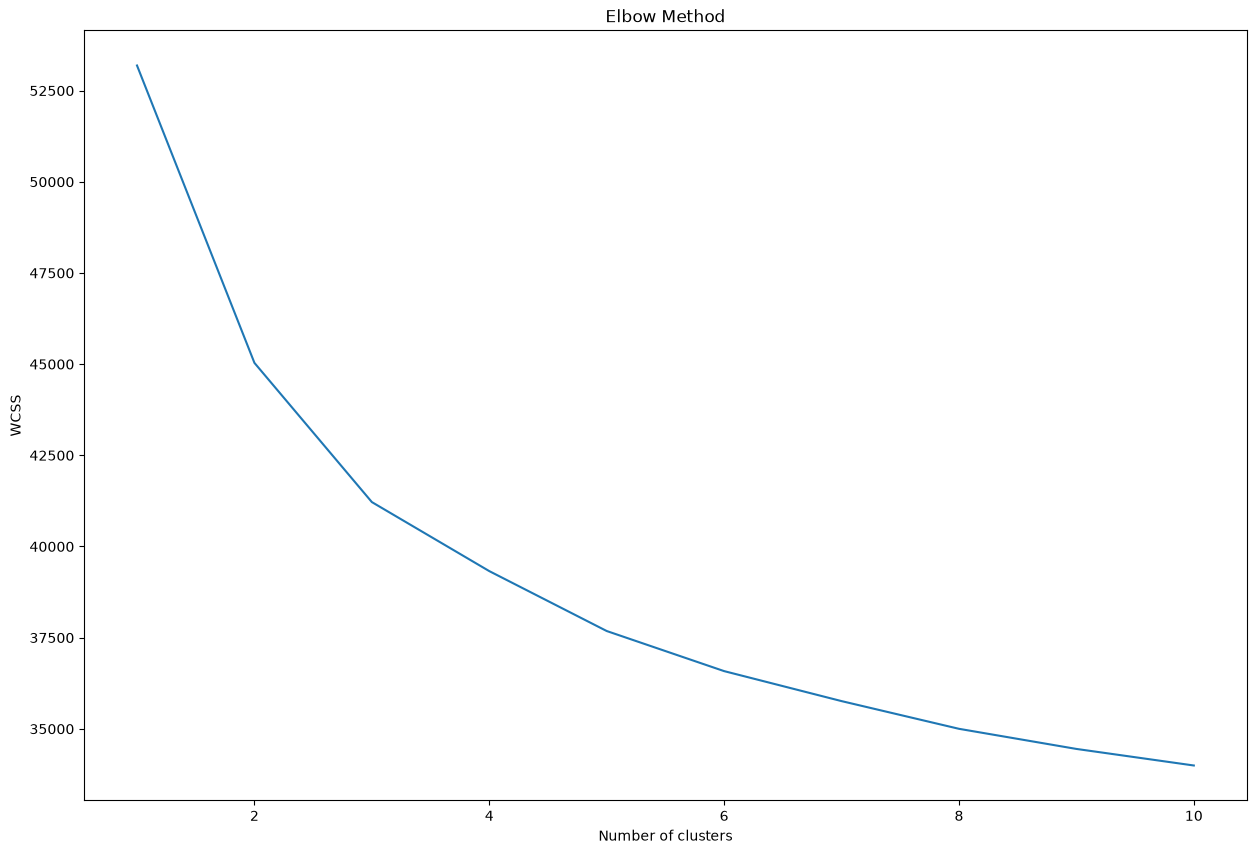

In [11]:
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init="k-means++", max_iter=150, n_init=10, random_state=0)
    kmeans.fit(X_pca)
    wcss.append(kmeans.inertia_)
plt.plot(range(1, 11), wcss)
plt.title("Elbow Method")
plt.xlabel("Number of clusters")
plt.ylabel("WCSS")
plt.show()

This time it is quite difficult to determine the right number of clusters from the plot alone. There are two relatively clear kinks at two and three clusters before the curve flattens, so it makes sense to decide on one of these numbers. In this case we are in a very comfortable situation because we know the right number of clusters, so we choose two as the number we want to work with.

Now we will fit our model to the data which earlier was reduced in its dimensionality with a PCA.

In [12]:
# Creating the KMeans Clustering model and fit it to our data X_pca after Dimensionality Reduction
kmeans = KMeans(n_clusters=2, verbose=0, init="k-means++", max_iter=150, n_init=20, random_state=0)
kmeans.fit(X_pca)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",2
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",20
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",150
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",0
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](2, 40)","[[-3.

Now we will plot the clusters and print our results. Since our data has more than three dimensions we will use t-SNE to reduce the dimensionality to visualize the results. 

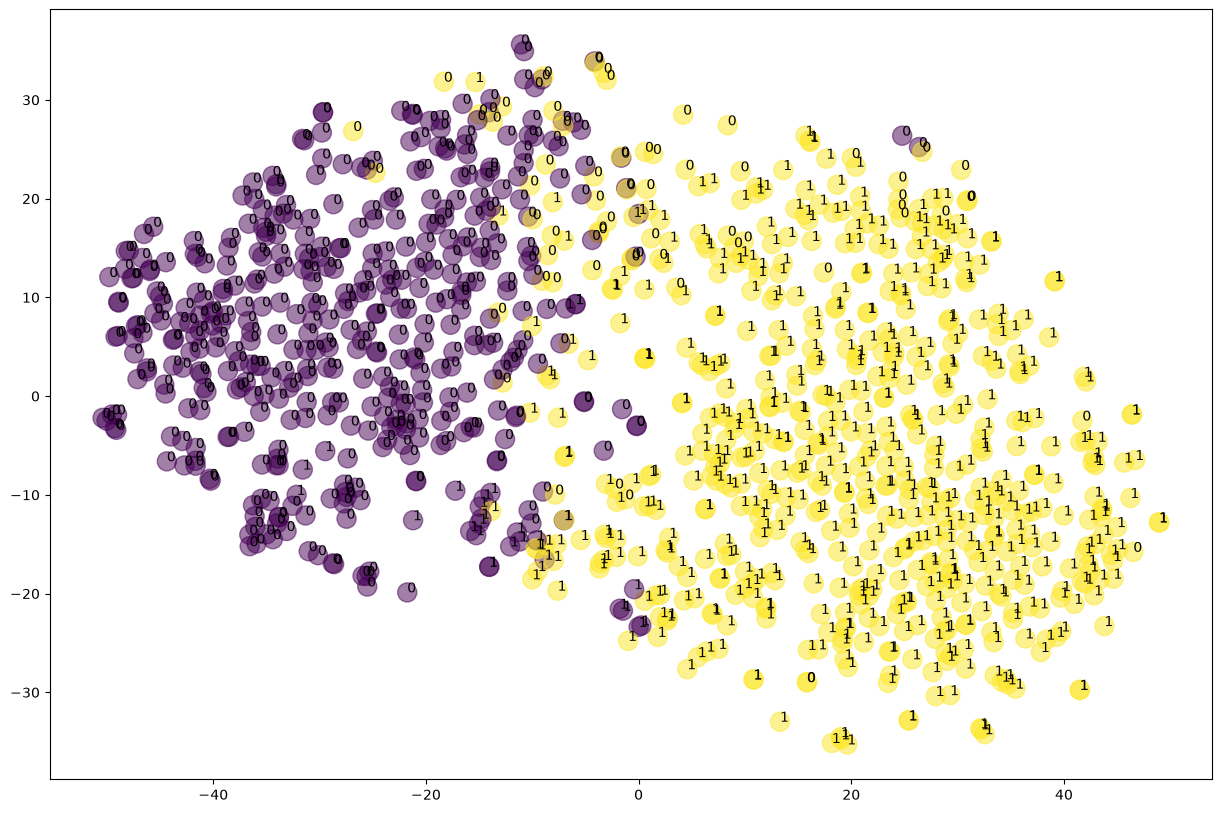

In [13]:
# Using t-SNE to prepare the data for plotting
model1 = TSNE(n_components=2, random_state=0)

Y = model1.fit_transform(X_pca)

plt.scatter(Y[:, 0], Y[:, 1], c=kmeans.labels_, s=190, alpha=0.5)
for j in range(len(sentences)):
    plt.annotate(data.target[j], xy=(Y[j][0], Y[j][1]), xytext=(0, 0), textcoords="offset points")

In [14]:
# Since we know the correct labels we can also evaluate the performance of the algorithm
print(confusion_matrix(data.target, kmeans.labels_))
print(classification_report(data.target, kmeans.labels_))

[[418  62]
 [ 29 565]]
              precision    recall  f1-score   support

           0       0.94      0.87      0.90       480
           1       0.90      0.95      0.93       594

    accuracy                           0.92      1074
   macro avg       0.92      0.91      0.91      1074
weighted avg       0.92      0.92      0.91      1074



According to the classification report the algorithm achieved an **accuracy** of only **8%**. BUT: Because Kmeans knows nothing about the identity of the clusters and assigns the initial centroids randomly, the labels may be permuted. To fix this we will perform the following steps:

In [15]:
# Create new dataframe with real and predicted labels
df_result = pd.DataFrame()
df_result["org_target"] = data.target
df_result["pred_target"] = kmeans.labels_
df_result.head()

,org_target,pred_target
0,0,0
1,0,0
2,0,0
3,1,0
4,1,1


In [16]:
# Switch 0s and 1s for predicted label
df_result["pred_target"].replace({1: 0, 0: 1}, inplace=True)
df_result.head()

/var/folders/26/qw1pnq493qv1_5s47r_4dd2r0000gn/T/ipykernel_98725/206638655.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df_result["pred_target"].replace({1: 0, 0: 1}, inplace=True)


,org_target,pred_target
0,0,0
1,0,0
2,0,0
3,1,0
4,1,1


In [17]:
# Evaluation metrics with fixed labels
print(confusion_matrix(df_result.org_target, df_result.pred_target))
print(classification_report(df_result.org_target, df_result.pred_target))

[[418  62]
 [ 29 565]]
              precision    recall  f1-score   support

           0       0.94      0.87      0.90       480
           1       0.90      0.95      0.93       594

    accuracy                           0.92      1074
   macro avg       0.92      0.91      0.91      1074
weighted avg       0.92      0.92      0.91      1074



Now, that looks better! As we can see Kmeans could cluster the texts pretty well with an **accuracy** of **92%**. 

Changing the labels manually is not always feasible, sometimes you will need an evaluation metric which is not sensitive to the permutation of the labels. One metric to choose in this situation is the [Rand Index](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.rand_score.html). It considers not the labels themselves, but their separation. It measure by some distance metric the similarity between the two label sets (the predicted one and the true labels).

In [20]:
from sklearn.metrics import adjusted_rand_score

print("Rand Index: {}".format(rand_score(data.target, kmeans.labels_)))
print("ARI: {}".format(adjusted_rand_score(data.target, kmeans.labels_)))

Rand Index: 0.8447538272234862
ARI: 0.6894203132575277


### MiniBatch KMeans

The second model we are using is `MiniBatchKMeans`. The MiniBatchKMeans is a variation of the KMeans algorithm which uses mini-batches to reduce the computation time, while still attempting to optimise the same objective function.

In [21]:
# Creating the MiniBatchKMeans Clustering model and fit it to our preprocessed data
batch_kmeans = MiniBatchKMeans(n_clusters=2, verbose=0, max_iter=150, n_init=20, random_state=0)
batch_kmeans.fit(X_pca)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.",2
,"max_iter max_iter: int, default=100Maximum number of iterations over the complete dataset beforestopping independently of any early stopping criterion heuristics.",150
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization andrandom reassignment. Use an int to make the randomness deterministic.See :term:`Glossary <random_state>`.",0
,"n_init n_init: 'auto' or int, default=""auto""Number of random initializations that are tried.In contrast to KMeans, the algorithm is only run once, using the best ofthe `n_init` initializations as measured by inertia. Several runs arerecommended for sparse high-dimensional problems (see:ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:3 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'` in version.",20
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:'k-means++' : selects initial cluster centroids using sampling based onan empirical probability distribution of the points' contribution to theoverall inertia. This technique speeds up convergence. The algorithmimplemented is ""greedy k-means++"". It differs from the vanilla k-means++by making several trials at each sampling step and choosing the best centroidamong them.'random': choose `n_clusters` observations (rows) at random from datafor the initial centroids.If an array is passed, it should be of shape (n_clusters, n_features)and gives the initial centers.If a callable is passed, it should take arguments X, n_clusters and arandom state and return an initialization.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"batch_size batch_size: int, default=1024Size of the mini batches.For faster computations, you can set `batch_size > 256 * number_of_cores`to enable :ref:`parallelism <lower-level-parallelism-with-openmp>`on all cores... versionchanged:: 1.0 `batch_size` default changed from 100 to 1024.",1024
,"verbose verbose: int, default=0Verbosity mode.",0
,"compute_labels compute_labels: bool, default=TrueCompute label assignment and inertia for the complete datasetonce the minibatch optimization has converged in fit.",True
,"tol tol: float, default=0.0Control early stopping based on the relative center changes asmeasured by a smoothed, variance-normalized of the mean centersquared position changes. This early stopping heuristics iscloser to the one used for the batch variant of the algorithmsbut induces a slight computational and memory overhead over theinertia heuristic.To disable convergence detection based on normalized centerchange, set tol to 0.0 (default).",0.0
,"max_no_improvement max_no_improvement: int, default=10Control early stopping based on the consecutive number of minibatches that does not yield an improvement on the smoothed inertia.To disable convergence detection based on inertia, setmax_no_improvement to None.",10
,"init_size init_size: int, default=NoneNumber of samples to randomly sample for speeding up theinitialization (sometimes at the expense of accuracy): theonly algorithm is initialized by running a batch KMeans on arandom subset of the data. This needs to be larger than n_clusters.If `None`, the heuristic is `init_size = 3 * batch_size` if`3 * batch_size < n_clusters`, else `init_size = 3 * n_clusters`.",None


In [27]:
print("ARI MiniBatch:", adjusted_rand_score(data.target, batch_kmeans.labels_))

ARI MiniBatch: 0.6617928965830799


Now we will plot the clusters and print our results.

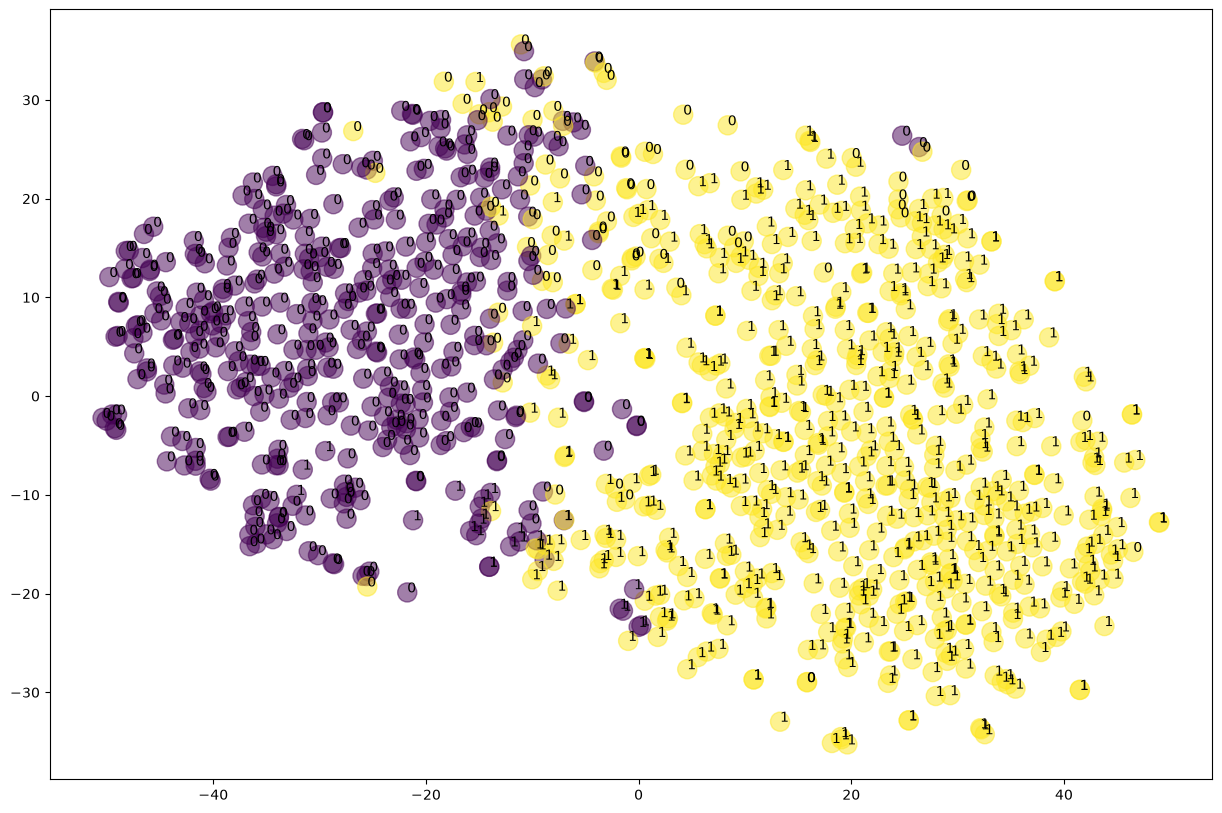

In [22]:
# Using t-SNE to prepare the data for plotting
model1 = TSNE(n_components=2, random_state=0)

Y = model1.fit_transform(X_pca)

plt.scatter(Y[:, 0], Y[:, 1], c=batch_kmeans.labels_, s=190, alpha=0.5)
for j in range(len(sentences)):
    plt.annotate(data.target[j], xy=(Y[j][0], Y[j][1]), xytext=(0, 0), textcoords="offset points")

In [23]:
flipped = 1 - kmeans.labels_
print("ARI flipped:", adjusted_rand_score(data.target, flipped))
print("accuracy flipped:", accuracy_score(data.target, flipped))

ARI flipped: 0.6894203132575277
accuracy flipped: 0.08472998137802606


In [24]:
print(confusion_matrix(data.target, batch_kmeans.labels_))
print(classification_report(data.target, batch_kmeans.labels_))

[[406  74]
 [ 26 568]]
              precision    recall  f1-score   support

           0       0.94      0.85      0.89       480
           1       0.88      0.96      0.92       594

    accuracy                           0.91      1074
   macro avg       0.91      0.90      0.90      1074
weighted avg       0.91      0.91      0.91      1074



Again, the clustering algorithm has reverse-mapped the class labels to the real labels. We can use the same procedure as above to fix this: 

In [25]:
# Define dataframe and change predicted target labels
df_result = pd.DataFrame()
df_result["org_target"] = data.target
df_result["pred_target"] = batch_kmeans.labels_
df_result["pred_target"].replace({1: 0, 0: 1}, inplace=True)
df_result.head()

/var/folders/26/qw1pnq493qv1_5s47r_4dd2r0000gn/T/ipykernel_98725/1403324288.py:5: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df_result["pred_target"].replace({1: 0, 0: 1}, inplace=True)


,org_target,pred_target
0,0,0
1,0,0
2,0,0
3,1,0
4,1,1


In [26]:
# Evaluation metrics with fixed labels
print(confusion_matrix(df_result.org_target, df_result.pred_target))
print(classification_report(df_result.org_target, df_result.pred_target))

[[406  74]
 [ 26 568]]
              precision    recall  f1-score   support

           0       0.94      0.85      0.89       480
           1       0.88      0.96      0.92       594

    accuracy                           0.91      1074
   macro avg       0.91      0.90      0.90      1074
weighted avg       0.91      0.91      0.91      1074



As we can see, MiniBatchKMeans reaches an **accuracy** of about **91%**, almost the same as K-Means. The mini-batch version trades a tiny amount of accuracy for a large gain in speed on big datasets.


### Agglomerative Clustering

The third algorithm we are going to use is `AgglomerativeClustering`. The AgglomerativeClustering object performs a hierarchical clustering using a bottom up approach: each observation starts in its own cluster, and clusters are successively merged together.

In [28]:
# Creating the AgglomerativeClustering model and fit it to our preprocessed data
agg_clust = AgglomerativeClustering(n_clusters=2, linkage="ward").fit(X_pca)

In [31]:
print("ARI Agglomerative:", adjusted_rand_score(data.target, agg_clust.labels_))

ARI Agglomerative: 0.6831684801814477


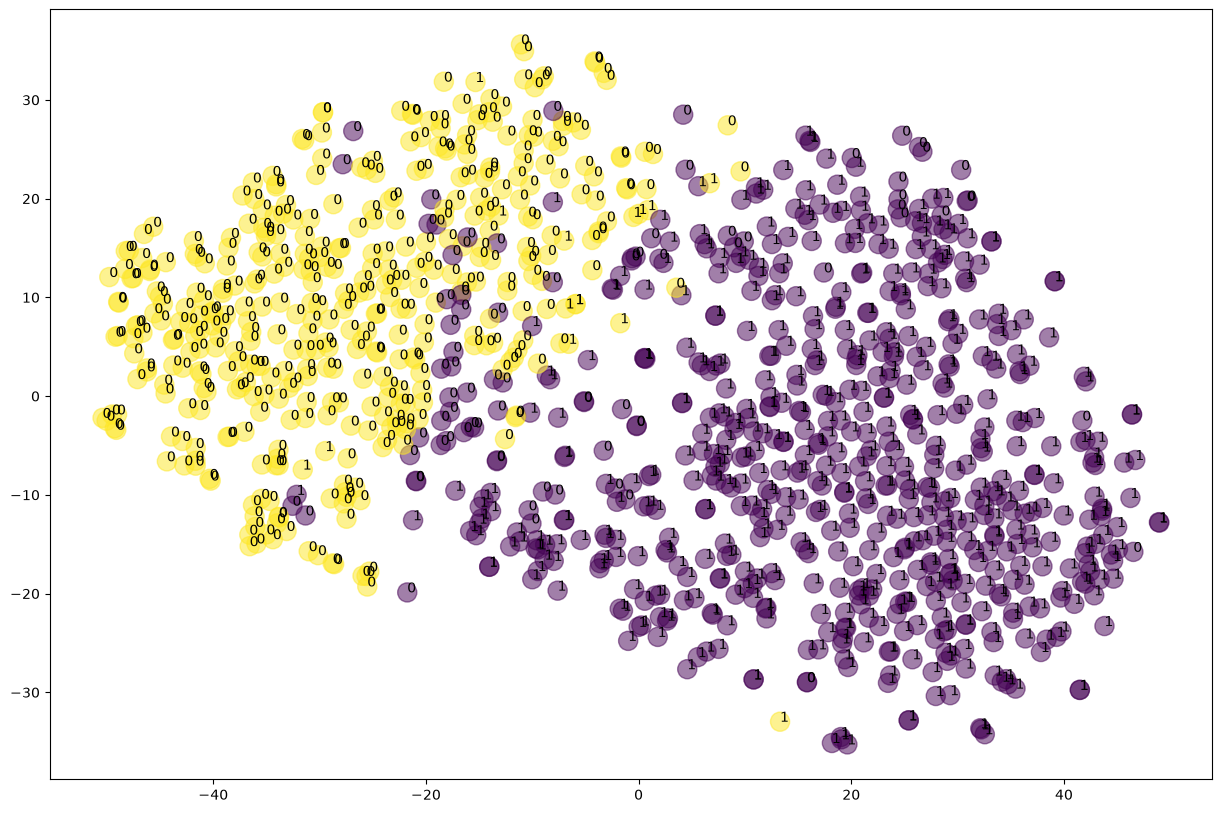

In [29]:
# Using t-SNE to prepare the data for plotting
model1 = TSNE(random_state=0)

Y = model1.fit_transform(X_pca)

plt.scatter(Y[:, 0], Y[:, 1], c=agg_clust.labels_, s=190, alpha=0.5)
for j in range(len(sentences)):
    plt.annotate(data.target[j], xy=(Y[j][0], Y[j][1]), xytext=(0, 0), textcoords="offset points")

In [30]:
print(confusion_matrix(data.target, agg_clust.labels_))
print(classification_report(data.target, agg_clust.labels_))

[[ 78 402]
 [579  15]]
              precision    recall  f1-score   support

           0       0.12      0.16      0.14       480
           1       0.04      0.03      0.03       594

    accuracy                           0.09      1074
   macro avg       0.08      0.09      0.08      1074
weighted avg       0.07      0.09      0.08      1074



Again, the clustering algorithm has reverse-mapped the class labels to the real labels. We can use the same procedure as above to fix this: 

In [32]:
# Define dataframe and change predicted target labels
df_result = pd.DataFrame()
df_result["org_target"] = data.target
df_result["pred_target"] = agg_clust.labels_
df_result["pred_target"].replace({1: 0, 0: 1}, inplace=True)
df_result.head()

/var/folders/26/qw1pnq493qv1_5s47r_4dd2r0000gn/T/ipykernel_98725/3421542800.py:5: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df_result["pred_target"].replace({1: 0, 0: 1}, inplace=True)


,org_target,pred_target
0,0,0
1,0,1
2,0,1
3,1,0
4,1,0


In [33]:
# Evaluate the AgglomerativeClustering algorithm
print(confusion_matrix(df_result.org_target, df_result.pred_target))
print(classification_report(df_result.org_target, df_result.pred_target))

[[ 78 402]
 [579  15]]
              precision    recall  f1-score   support

           0       0.12      0.16      0.14       480
           1       0.04      0.03      0.03       594

    accuracy                           0.09      1074
   macro avg       0.08      0.09      0.08      1074
weighted avg       0.07      0.09      0.08      1074



As you can see `AgglomerativeClustering` performed similarly to the other algorithms achieving an **accuracy** of **91%**. 

### Exercise: DBSCAN

We also tried `DBSCAN` on the data, but it performed relatively poorly. You are welcome to try it yourself.

Remember to tune the hyperparameters of DBSCAN to get different results (you should definitely do this if every point ends up in a single cluster).

If you check the classification report, you will notice a `-1` "cluster". This is not a cluster: it holds all the points the algorithm considers noise.


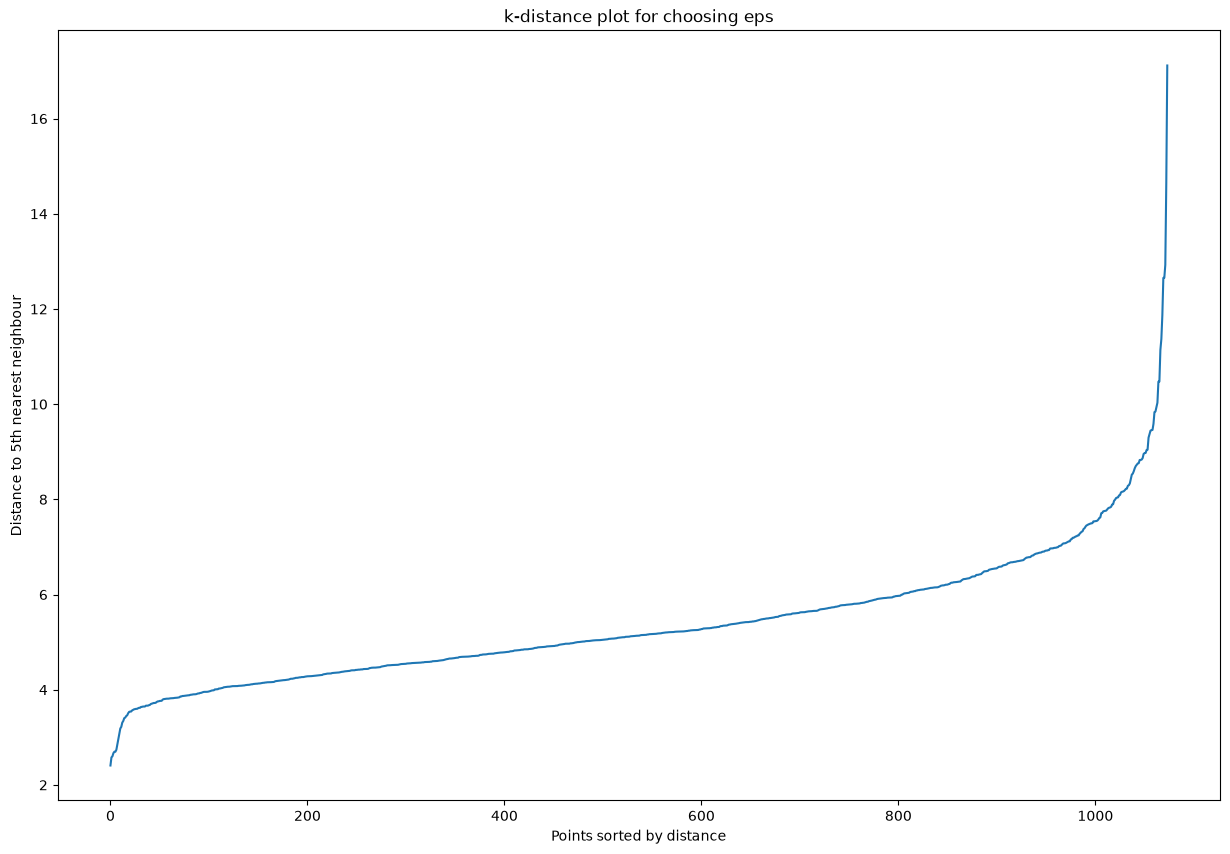

In [34]:
from sklearn.neighbors import NearestNeighbors

neigh = NearestNeighbors(n_neighbors=5).fit(X_pca)
dist, _ = neigh.kneighbors(X_pca)
dist = np.sort(dist[:, -1])

plt.plot(dist)
plt.xlabel("Points sorted by distance")
plt.ylabel("Distance to 5th nearest neighbour")
plt.title("k-distance plot for choosing eps")
plt.show()

In [35]:
from sklearn.cluster import DBSCAN

for eps in [3, 7.5, 10]:
    dbscan_labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X_pca)
    n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
    n_noise = int((dbscan_labels == -1).sum())
    ari = adjusted_rand_score(data.target, dbscan_labels)
    print(f"eps={eps}: clusters={n_clusters}, noise={n_noise} of {len(dbscan_labels)}, ARI={ari:.3f}")

eps=3: clusters=2, noise=1063 of 1074, ARI=0.000
eps=7.5: clusters=1, noise=45 of 1074, ARI=-0.007
eps=10: clusters=1, noise=7 of 1074, ARI=-0.002


In [36]:
print("X_pca shape:", X_pca.shape)

for eps in np.arange(3.5, 7.5, 0.5):
    dbscan_labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X_pca)
    n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
    n_noise = int((dbscan_labels == -1).sum())
    ari = adjusted_rand_score(data.target, dbscan_labels)
    print(f"eps={eps:.1f}: clusters={n_clusters}, noise={n_noise}, ARI={ari:.3f}")

X_pca shape: (1074, 40)
eps=3.5: clusters=5, noise=1039, ARI=0.001
eps=4.0: clusters=8, noise=839, ARI=0.039
eps=4.5: clusters=3, noise=630, ARI=0.014
eps=5.0: clusters=1, noise=422, ARI=0.005
eps=5.5: clusters=1, noise=263, ARI=-0.002
eps=6.0: clusters=1, noise=175, ARI=-0.006
eps=6.5: clusters=1, noise=103, ARI=-0.008
eps=7.0: clusters=1, noise=63, ARI=-0.008


### Conclusion of the DBSCAN exercise

**Choosing eps.** The sorted 5th-nearest-neighbour distances rise smoothly from about 2.5 to about 7.5 and only bend sharply around 7.5 to 10. Unlike the 2D data in notebook 1, there is no flat low part followed by a jump, so no region is clearly denser than its surroundings. (The reference solution uses eps=3, but in this plot only about 10 points have their 5th neighbour within 3, so that value does not come from the elbow.)

**Result.** No eps separates the two topics:

| eps | clusters | noise (of 1074) | ARI |
|---|---|---|---|
| 3.0 | 2 | 1063 | 0.000 |
| 4.0 | 8 | 839 | 0.039 |
| 5.0 | 1 | 422 | 0.005 |
| 7.5 | 1 | 45 | -0.007 |
| 10 | 1 | 7 | -0.002 |

Small eps labels almost everything as noise, larger eps merges both topics into one cluster; there is no value in between that gives two large clusters. The best ARI (0.039) is at chance level, compared with 0.689 for KMeans, 0.683 for Agglomerative and 0.662 for MiniBatchKMeans.

**Why.** After PCA the documents still live in 40 dimensions, where all points are roughly equally far apart (curse of dimensionality). DBSCAN needs dense regions separated by sparse gaps, and here the two topics are connected without such a gap. KMeans only asks which centroid is closer, so it still works.

**Side note.** The label-swap cells use `df["col"].replace(..., inplace=True)`, which does nothing under pandas 3.0 (copy-on-write). In this run KMeans already named the clusters correctly (accuracy 0.92 before the swap), so the broken swap left the right answer by luck. ARI gives the same value (0.689) for original and flipped labels, so it avoids this trap completely.

## Summary

In this notebook you:

- Constructed sentence embeddings by averaging word vectors from Word2Vec and GloVe.
- Applied K-Means, MiniBatchKMeans, and Agglomerative clustering to the embedded 20 Newsgroups texts.
- Evaluated the clusters with confusion matrices, accuracy (about 91 to 92%), and the Rand index (about 0.85).
- Compared the three algorithms and saw that they performed similarly on this two-topic dataset.

Because the cluster labels are arbitrary, remember to either align them to the true labels before scoring accuracy, or use a permutation-invariant metric such as the Rand index.


## References & Further Reading

- [**gensim: Word2Vec**](https://radimrehurek.com/gensim/models/word2vec.html): documentation for the Word2Vec model used here.
- [**GloVe: Global Vectors for Word Representation**](https://nlp.stanford.edu/projects/glove/): the original Stanford project page.
- [**scikit-learn: the 20 newsgroups text dataset**](https://scikit-learn.org/stable/datasets/real_world.html#the-20-newsgroups-text-dataset): the dataset used for the GloVe experiments.
- [**scikit-learn: Rand index**](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.rand_score.html): the permutation-invariant metric used to score the clustering.
